# Qwen3-30B-A3B: all-Marlin + LoRA

Minimal backend experiment based on `qlora-Qwen3-30B-A3B_train.ipynb`. Physical GPU **2** only. All quantized projections use the same backend; no per-layer replacements, custom kernels, or dtype hooks.

First check native forward speed and input gradients, then try normal `model.train()`. Only run SFT when both checks pass. A decreasing loss with a broken base-path gradient is **not** successful QLoRA. This notebook isolates the backend before adding TransformerLens, dependency tracing or pruning. The source notebook is unchanged.

## Executed result — 2026-11-09
All **18,624** quantized projections loaded as MarlinLinear, with PEFT GPTQLoraLinear adapters in layers 45–47. Native FP16 forward + loss: **1.78 s** at batch 1 and **2.42 s** at batch 8 (128 tokens; three timed repetitions after warmup). Batch-8 throughput: **3.31 examples/s**, peak allocated memory: **17.21 GiB**. These are inference measurements, not optimizer-step timings.

**Training blocked:** the actual Marlin input gradient is `None`; PyTorch reports that no autograd kernel is registered. An independent directional derivative is nonzero (-90.77), so a missing input gradient is not valid. Normal `train()` also raises NotImplementedError. No optimizer steps or training curves were produced. The guarded SFT cell is a template, not a validated training recipe. No package upgrades, per-layer backend changes, or backward overrides were made.

Runtime setup: the existing venv Ninja needed to be added to PATH. The standard Marlin FP16 JIT compilation took 177 s once; this is excluded from timing. Recorded results: `all_marlin_20261109_152919/results.json`; each rerun prints its own output directory below.

In [1]:
import os
import sys
os.environ['PATH'] = os.path.dirname(sys.executable) + os.pathsep + os.environ['PATH']  # JIT finds the venv's ninja.
os.environ['CUDA_VISIBLE_DEVICES'] = '2'  # Set before importing torch; restart an existing kernel.
os.environ.setdefault('HF_HUB_CACHE', '/glazkov-dev/.cache')
os.environ['HF_HUB_OFFLINE'] = '1'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'

import json
import time
import warnings
from collections import Counter
from pathlib import Path
from unittest.mock import patch
import importlib.metadata as metadata
import torch
import pandas as pd
import matplotlib.pyplot as plt
from gptqmodel import GPTQModel
from gptqmodel.utils.backend import BACKEND
from gptqmodel.nn_modules.qlinear import BaseQuantLinear
from peft import LoraConfig, TaskType, get_peft_model
from transformers import AutoTokenizer, DataCollatorForLanguageModeling, set_seed
from datasets import Dataset
from trl import SFTConfig, SFTTrainer

MODEL = 'Qwen/Qwen3-30B-A3B-GPTQ-Int4'
BACKEND_CHOICE = BACKEND.GPTQ_MARLIN
CONTEXT_LENGTH, BATCH_SIZE, NUM_STEPS = 128, 8, 20
set_seed(0)
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'lora_transfer_pruning').is_dir())
RESULT_DIR = ROOT / 'experiments/qlora/slop_experiments/3_slop_marlin_lora_gptq_speed' / ('all_marlin_' + time.strftime('%Y%m%d_%H%M%S'))
RESULT_DIR.mkdir(parents=True, exist_ok=False)
results = {'versions': {p: metadata.version(p) for p in ('torch', 'gptqmodel', 'peft', 'transformers', 'trl')}, 'gpu': torch.cuda.get_device_name(0), 'physical_gpu': 2, 'timings': []}
print(results)
print('Results:', RESULT_DIR)


WARN  Python GIL is enabled: Multi-gpu quant acceleration for MoE models is sub-optimal and multi-core accelerated cpu packing is also disabled. We recommend Python >= 3.13.3t with Pytorch > 2.8 for mult-gpu quantization and multi-cpu packing with env `PYTHON_GIL=0`.

Skipping import of cpp extensions due to incompatible torch version. Please upgrade to torch >= 2.11.0 (found 2.10.0+cu128).


INFO  ENV: Auto setting PYTORCH_ALLOC_CONF='expandable_segments:True,max_split_size_mb:256,garbage_collection_threshold:0.7' for memory saving.

INFO  ENV: Auto setting CUDA_DEVICE_ORDER=PCI_BUS_ID for correctness.          

INFO:datasets:PyTorch version 2.10.0+cu128 available.


INFO  

┌─────────────┐    ┌────────────────────────┐    ┌────────────┐    ┌─────────┐
│ GPT-QModel  │ -> │ ▓▓▓▓▓▓▓▓▓▓▓▓ 16bit     │ -> │ ▒▒▒▒ 8bit  │ -> │ ░░ 4bit │
└─────────────┘    └────────────────────────┘    └────────────┘    └─────────┘
GPT-QModel   : 7.0.0+7b8f06e
Transformers : 5.9.0
Torch        : 2.10.0+cu128
Triton       : 3.6.0

{'versions': {'torch': '2.10.0+cu128', 'gptqmodel': '7.0.0', 'peft': '0.20.0', 'transformers': '5.9.0', 'trl': '0.29.1'}, 'gpu': 'NVIDIA A100-PCIE-40GB', 'physical_gpu': 2, 'timings': []}
Results: /glazkov-dev/LoRa-Transfer-Pruning/experiments/qlora/results/all_marlin_20261109_152919


In [2]:
started = time.perf_counter()
quantized_model = GPTQModel.load(MODEL, device='cuda:0', backend=BACKEND_CHOICE, dtype=torch.float16)
hf_model = quantized_model.model
hf_model.config.use_cache = False
results['load_seconds'] = time.perf_counter() - started
results['quantized_module_types'] = dict(Counter(type(m).__name__ for m in hf_model.modules() if isinstance(m, BaseQuantLinear)))
print('Quantized modules:', results['quantized_module_types'])
print('Load seconds:', results['load_seconds'])
assert set(results['quantized_module_types']) == {'MarlinLinear'}, 'Unexpected backend fallback'


from_quantized: adapter: None


INFO  Patched transformers.models.qwen3_moe.modeling_qwen3_moe.Qwen3MoeSparseMoeBlock -> defuser.modeling.unfused_moe.qwen3_moe.LinearQwen3MoeSparseMoeBlock

INFO  QuantizeConfig: Ignoring unknown parameter in the quantization configuration: model_name_or_path.

INFO  QuantizeConfig: Ignoring unknown parameter in the quantization configuration: model_file_base_name.

INFO  QuantizeConfig: offload_to_disk_path auto set to temporary dir `/tmp/gptqmodel_520kvpz1`

INFO  Estimated Quantization BPW (bits per weight): 4.2875 bpw, based on [bits: 4, group_size: 128]

... (13 outputs left out)

INFO  Model: Auto-fixed `generation_config` mismatch between model and `generation_config.json`.

INFO  Model: Updated `generation_config`: GenerationConfig {
  "bos_token_id": 151643,
  "do_sample": true,
  "eos_token_id": [
    151645,
    151643
  ],
  "temperature": 0.6,
  "top_k": 20,
  "top_p": 0.95
}


INFO  Kernel: loaded -> `[MarlinLinear]`                                       

Quantized modules: {'MarlinLinear': 18624}
Load seconds: 208.55482257530093


## Data and LoRA
Same LoRA targets and rank as the source notebook. Use local WikiText paragraphs; split documents before tokenization. Timing uses eight different paragraphs, not repeated copies (important for MoE routing). FP16 base computation, no BF16 autocast. PEFT may intentionally keep adapter parameters in FP32.

In [3]:
import pyarrow.parquet as pq
tokenizer = AutoTokenizer.from_pretrained(MODEL)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
parquet = next((Path(os.environ['HF_HUB_CACHE']) / 'datasets--Salesforce--wikitext/snapshots').glob('*/wikitext-2-raw-v1/validation-00000-of-00001.parquet'))
texts = [t for t in pq.read_table(parquet, columns=['text'])['text'].to_pylist() if len(t) > 1000]
raw = Dataset.from_dict({'text': texts}).train_test_split(test_size=0.2, seed=42)
def tokenize(batch):
    return tokenizer(batch['text'], truncation=True, max_length=CONTEXT_LENGTH, padding=False)
tokenized = raw.map(tokenize, batched=True, remove_columns=['text'])
train_dataset = tokenized['train'].select(range(min(64, len(tokenized['train']))))
eval_dataset = tokenized['test'].select(range(min(8, len(tokenized['test']))))
data_collator = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm=False)
timing_batch = tokenizer(texts[:BATCH_SIZE], truncation=True, max_length=CONTEXT_LENGTH, padding='max_length', return_tensors='pt').to('cuda:0')
timing_batch['labels'] = timing_batch.input_ids.masked_fill(timing_batch.attention_mask == 0, -100)

lora_config = LoraConfig(task_type=TaskType.CAUSAL_LM, r=16, lora_alpha=32, lora_dropout=0.0, bias='none',
                         target_parameters=[], layers_to_transform=[45, 46, 47],
                         target_modules=['q_proj', 'k_proj', 'v_proj', 'o_proj', 'up_proj', 'down_proj', 'gate_proj'])
# Same existing compatibility patch as the source: GPTQ experts are modules, not fused Parameters.
with patch('peft.utils.transformers_weight_conversion.convert_peft_config_for_transformers', return_value=None):
    model = get_peft_model(quantized_model, lora_config)
hf_model = model.base_model.model.model
model.print_trainable_parameters()
print('LoRA wrapper:', type(hf_model.model.layers[45].self_attn.q_proj).__name__)
print('Base dtype:', hf_model.model.embed_tokens.weight.dtype)
print('Adapter dtype:', hf_model.model.layers[45].self_attn.q_proj.lora_A['default'].weight.dtype)


Map:   0%|          | 0/245 [00:00<?, ? examples/s]

Map:   0%|          | 0/62 [00:00<?, ? examples/s]

trainable params: 52,740,096 || all params: 4,658,558,976 || trainable%: 1.1321
LoRA wrapper: GPTQLoraLinear
Base dtype: torch.float16
Adapter dtype: torch.float32


In [4]:
hf_model.eval()
for size in (1, BATCH_SIZE):
    batch = {k: v[:size] for k, v in timing_batch.items()}
    with torch.no_grad():
        hf_model(**batch, use_cache=False)  # warm up, excluding JIT/load time
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()
        times = []
        for _ in range(3):
            start = time.perf_counter()
            output = hf_model(**batch, use_cache=False)
            torch.cuda.synchronize()
            times.append(time.perf_counter() - start)
            loss = output.loss.item()
            del output
    row = {'batch_size': size, 'seconds': sum(times) / len(times), 'samples_per_second': size / (sum(times) / len(times)),
           'peak_allocated_gib': torch.cuda.max_memory_allocated() / 2**30, 'loss': loss, 'repeats': times}
    results['timings'].append(row)
    print(row)


{'batch_size': 1, 'seconds': 1.7780344498654206, 'samples_per_second': 0.562418799070901, 'peak_allocated_gib': 15.93675184249878, 'loss': 2.9439167976379395, 'repeats': [1.8136141188442707, 1.7672568149864674, 1.753232415765524]}


{'batch_size': 8, 'seconds': 2.419074922800064, 'samples_per_second': 3.3070492875599116, 'peak_allocated_gib': 17.208128452301025, 'loss': 2.5596110820770264, 'repeats': [2.4152750484645367, 2.4012242816388607, 2.440725438296795]}


## Training safety check
A frozen base weight still needs an input gradient to train earlier adapters. Test one actual Marlin base projection without LoRA. No overriding `SUPPORTS_TRAINING`, `train()`, or backward. The random directional derivative provides an independent nonzero reference using linearity, without unpacking the weight.

In [5]:
base = hf_model.model.layers[45].self_attn.q_proj.base_layer
x = torch.randn(2, base.in_features, device='cuda:0', dtype=torch.float16, requires_grad=True)
direction = torch.randn_like(x)
with torch.no_grad():
    cotangent = torch.randn(2, base.out_features, device=x.device, dtype=x.dtype)
    expected_directional = ((base(direction) - base(torch.zeros_like(direction))).float() * cotangent.float()).sum().item()
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    try:
        y = base(x)
        dx, = torch.autograd.grad(y, x, grad_outputs=cotangent, allow_unused=True)
        measured_directional = None if dx is None else (dx.float() * direction.float()).sum().item()
        input_grad_ok = dx is not None and bool(torch.isfinite(dx).all()) and abs(measured_directional - expected_directional) <= 0.05 + 0.02 * abs(expected_directional)
        results['input_gradient'] = {'ok': input_grad_ok, 'is_none': dx is None, 'max_abs': None if dx is None else dx.abs().max().item(), 'expected_directional': expected_directional, 'measured_directional': measured_directional}
    except (RuntimeError, NotImplementedError) as exc:
        input_grad_ok = False
        results['input_gradient'] = {'ok': False, 'error': str(exc), 'expected_directional': expected_directional}
    results['autograd_warnings'] = [str(w.message) for w in caught]
try:
    hf_model.train()
    train_mode_ok = True
    results['train_mode'] = {'ok': True}
except (RuntimeError, NotImplementedError) as exc:
    train_mode_ok = False
    results['train_mode'] = {'ok': False, 'error': str(exc)}
finally:
    hf_model.eval()
can_train = input_grad_ok and train_mode_ok
results['can_train'] = can_train
print(json.dumps({k: results[k] for k in ('input_gradient', 'autograd_warnings', 'train_mode', 'can_train')}, indent=2))
(RESULT_DIR / 'results.json').write_text(json.dumps(results, indent=2))


ERROR MarlinLinear: `model.layers.0.self_attn.q_proj` switching to training mode.

{
  "input_gradient": {
    "ok": false,
    "is_none": true,
    "max_abs": null,
    "expected_directional": -90.77268981933594,
    "measured_directional": null
  },
  "autograd_warnings": [
    "gptqmodel_marlin_fp16::gptq_marlin_gemm_fp16: an autograd kernel was not registered to the Autograd key(s) but we are trying to backprop through it. This may lead to silently incorrect behavior. This behavior is deprecated and will be removed in a future version of PyTorch. If your operator is differentiable, please ensure you have registered an autograd kernel to the correct Autograd key (e.g. DispatchKey::Autograd, DispatchKey::CompositeImplicitAutograd). If your operator is not differentiable, or to squash this warning and use the previous behavior, please register torch::CppFunction::makeFallthrough() to DispatchKey::Autograd. (Triggered internally at /pytorch/torch/csrc/autograd/autograd_not_implemented_fallback.cpp:76.)"
  ],
  "train_mode": {
    "ok": false,
    "error": "MarlinLine

2035

In [6]:
history = []
if not can_train:
    print('BLOCKED: all-Marlin does not pass native training checks. No optimizer steps; no misleading training curve.')
else:
    args = SFTConfig(output_dir=str(RESULT_DIR), max_steps=NUM_STEPS, learning_rate=3e-4,
        per_device_train_batch_size=BATCH_SIZE, per_device_eval_batch_size=BATCH_SIZE,
        gradient_accumulation_steps=1, gradient_checkpointing=False, fp16=False, bf16=False,
        logging_steps=1, logging_first_step=True, eval_strategy='steps', eval_steps=5,
        save_strategy='no', report_to='none', prediction_loss_only=True, seed=0,
        dataset_kwargs={'skip_prepare_dataset': True})
    optimizer = torch.optim.SGD((p for p in hf_model.parameters() if p.requires_grad), lr=3e-4, momentum=0.9, nesterov=True)
    trainer = SFTTrainer(model=hf_model, args=args, train_dataset=train_dataset, eval_dataset=eval_dataset,
        processing_class=tokenizer, data_collator=data_collator, optimizers=(optimizer, None))
    print('Before training:', trainer.evaluate())
    trainer.train()
    print('After training:', trainer.evaluate())
    history = trainer.state.log_history
    (RESULT_DIR / 'history.json').write_text(json.dumps(history, indent=2))


BLOCKED: all-Marlin does not pass native training checks. No optimizer steps; no misleading training curve.


,batch_size,seconds,samples_per_second,peak_allocated_gib,loss
0,1,1.778034,0.562419,15.936752,2.943917
1,8,2.419075,3.307049,17.208128,2.559611


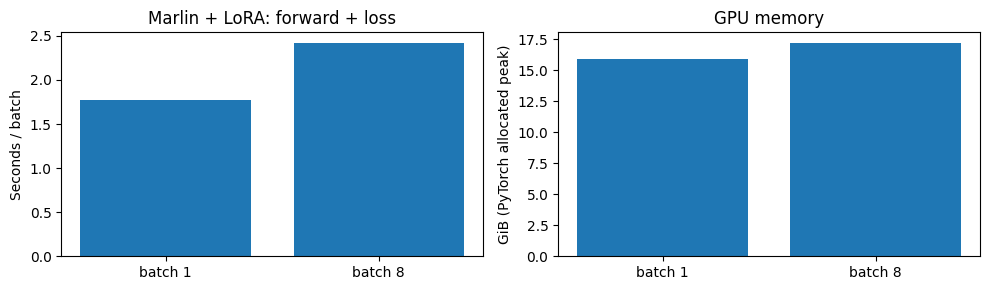

In [7]:
timings = pd.DataFrame(results['timings'])
display(timings.drop(columns='repeats'))
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
labels = ['batch ' + str(n) for n in timings.batch_size]
axes[0].bar(labels, timings.seconds)
axes[0].set(ylabel='Seconds / batch', title='Marlin + LoRA: forward + loss')
axes[1].bar(labels, timings.peak_allocated_gib)
axes[1].set(ylabel='GiB (PyTorch allocated peak)', title='GPU memory')
plt.tight_layout()
plt.show()
if history:
    frame = pd.DataFrame(history)
    fig, ax = plt.subplots(figsize=(8, 3))
    for key in ('loss', 'eval_loss'):
        if key in frame:
            rows = frame.dropna(subset=[key])
            ax.plot(rows.step, rows[key], marker='o', label=key)
    ax.set(xlabel='Optimizer step', ylabel='Cross entropy', title='LoRA training (only after gradient checks pass)')
    ax.legend()
    plt.show()
